# Rail Data - Initial Time Series EDA

This notebook loads the Supabase export and starts by understanding the data format, especially timestamp fields, before running a quick exploratory analysis.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

DATA_PATH = Path("../dataset/supabase/rail_data_rows_27march.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find dataset at: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

# Drop columns not needed for analysis.
cols_to_drop = ["distance_from_origin_km", "created_at", "updated_at"]
df = df.drop(columns=cols_to_drop, errors="ignore")

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH}")
print(f"Dropped columns (if present): {cols_to_drop}")
df.head(10)

Loaded 30,799 rows and 10 columns from ..\dataset\supabase\rail_data_rows_27march.csv
Dropped columns (if present): ['distance_from_origin_km', 'created_at', 'updated_at']


,id,train_no,journey_date,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,delay_arrival_minutes,delay_departure_minutes
0,1,61631,2026-01-17,BPL,1768615200,1.768615e+09,NaN,1.768616e+09,NaN,10.0
1,2,61631,2026-01-17,SUW,1768616040,1.768616e+09,1.768616e+09,1.768617e+09,6.0,11.0
2,3,61631,2026-01-17,BVB,1768616640,1.768617e+09,NaN,1.768617e+09,NaN,6.0
3,4,61631,2026-01-17,DWG,1768617180,1.768617e+09,1.768618e+09,1.768618e+09,7.0,10.0
4,5,61631,2026-01-17,SMT,1768617720,1.768618e+09,1.768618e+09,1.768618e+09,10.0,12.0
5,6,61631,2026-01-17,SCI,1768618140,1.768618e+09,1.768619e+09,1.768619e+09,12.0,14.0
6,7,61631,2026-01-17,BHS,1768618800,1.768619e+09,1.768620e+09,1.768620e+09,14.0,17.0
7,8,61631,2026-01-17,SUMR,1768619880,1.768620e+09,1.768621e+09,1.768621e+09,16.0,20.0
8,9,61631,2026-01-17,GLG,1768620360,1.768620e+09,1.768621e+09,1.768622e+09,18.0,20.0
9,10,61631,2026-01-17,PAI,1768621080,1.768621e+09,1.768623e+09,1.768623e+09,26.0,31.0


In [3]:
# 1) Understand raw format after dropping non-analysis columns
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values (%):")
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct.to_frame("missing_percent"))

# 2) Parse unix timestamp columns and convert them to IST as per schema definition.
unix_time_cols = [
    "scheduled_arrival",
    "scheduled_departure",
    "actual_arrival",
    "actual_departure",
]
unix_time_cols = [c for c in unix_time_cols if c in df.columns]

parse_rows = []
for c in unix_time_cols:
    parsed_utc = pd.to_datetime(df[c], unit="s", errors="coerce", utc=True)
    parsed_ist = parsed_utc.dt.tz_convert("Asia/Kolkata")

    df[f"{c}_ist"] = parsed_ist

    parse_rows.append(
        {
            "column": c,
            "valid_ratio": parsed_ist.notna().mean(),
            "nunique_timestamps": parsed_ist.nunique(dropna=True),
            "min_time_ist": parsed_ist.min(),
            "max_time_ist": parsed_ist.max(),
        }
    )

parse_report_df = pd.DataFrame(parse_rows)
if parse_report_df.empty:
    raise ValueError("No unix timestamp columns found for time-series analysis.")

parse_report_df = parse_report_df.sort_values(
    ["valid_ratio", "nunique_timestamps"],
    ascending=[False, False],
).reset_index(drop=True)

print("\nUnix timestamp parse quality (IST):")
display(parse_report_df)

# Prefer actual times first, then scheduled times for event-time axis.
preferred_time_cols = [
    "actual_departure",
    "actual_arrival",
    "scheduled_departure",
    "scheduled_arrival",
]
selected_base_col = None
for c in preferred_time_cols:
    hit = parse_report_df.loc[(parse_report_df["column"] == c) & (parse_report_df["valid_ratio"] > 0)]
    if not hit.empty:
        selected_base_col = c
        break
if selected_base_col is None:
    selected_base_col = parse_report_df.iloc[0]["column"]

time_col = f"{selected_base_col}_ist"
df["_event_time"] = df[time_col]
df = df.dropna(subset=["_event_time"]).sort_values("_event_time").reset_index(drop=True)

# Keep journey_date as date for grouping/reporting consistency.
if "journey_date" in df.columns:
    df["journey_date"] = pd.to_datetime(df["journey_date"], errors="coerce").dt.date

print(f"\nUsing '{selected_base_col}' converted to IST as time axis")
print(f"Valid timestamp rows: {len(df):,}")
print(f"Time range (IST): {df['_event_time'].min()} to {df['_event_time'].max()}")

print("\nParsed timestamp preview (IST):")
preview_cols = [c for c in ["train_no", "journey_date", "station_code", "_event_time"] if c in df.columns]
preview_cols += [f"{c}_ist" for c in unix_time_cols]
display(df[preview_cols].head(8))

# Gap diagnostics for time series cadence in IST event time.
time_gaps = df["_event_time"].diff().dropna()
if not time_gaps.empty:
    print("\nTypical time gap between consecutive records:")
    print(time_gaps.describe())

Column names:
['id', 'train_no', 'journey_date', 'station_code', 'scheduled_arrival', 'scheduled_departure', 'actual_arrival', 'actual_departure', 'delay_arrival_minutes', 'delay_departure_minutes']

Data types:


,dtype
id,int64
train_no,int64
journey_date,str
station_code,str
scheduled_arrival,int64
scheduled_departure,float64
actual_arrival,float64
actual_departure,float64
delay_arrival_minutes,float64
delay_departure_minutes,float64



Missing values (%):


,missing_percent
actual_departure,9.909413
delay_departure_minutes,9.909413
delay_arrival_minutes,3.487126
actual_arrival,3.477386
scheduled_departure,2.194876
id,0.000000
train_no,0.000000
scheduled_arrival,0.000000
journey_date,0.000000
station_code,0.000000



Unix timestamp parse quality (IST):


,column,valid_ratio,nunique_timestamps,min_time_ist,max_time_ist
0,scheduled_arrival,1.000000,26108,2026-01-17 07:30:00+05:30,2026-03-27 05:15:00+05:30
1,scheduled_departure,0.978051,25230,2026-01-17 07:30:00+05:30,2026-03-27 04:07:00+05:30
2,actual_arrival,0.965226,29658,2026-01-17 07:49:39+05:30,2026-03-27 05:16:12+05:30
3,actual_departure,0.900906,27680,2026-01-17 07:40:20+05:30,2026-03-27 04:47:10+05:30



Using 'actual_departure' converted to IST as time axis
Valid timestamp rows: 27,747
Time range (IST): 2026-01-17 07:40:20+05:30 to 2026-03-27 04:47:10+05:30

Parsed timestamp preview (IST):


,train_no,journey_date,station_code,_event_time,scheduled_arrival_ist,scheduled_departure_ist,actual_arrival_ist,actual_departure_ist
0,61631,2026-01-17,BPL,2026-01-17 07:40:20+05:30,2026-01-17 07:30:00+05:30,2026-01-17 07:30:00+05:30,NaT,2026-01-17 07:40:20+05:30
1,61631,2026-01-17,SUW,2026-01-17 07:56:15+05:30,2026-01-17 07:44:00+05:30,2026-01-17 07:45:00+05:30,2026-01-17 07:49:39+05:30,2026-01-17 07:56:15+05:30
2,61631,2026-01-17,BVB,2026-01-17 08:01:00+05:30,2026-01-17 07:54:00+05:30,2026-01-17 07:55:00+05:30,NaT,2026-01-17 08:01:00+05:30
3,61631,2026-01-17,DWG,2026-01-17 08:14:10+05:30,2026-01-17 08:03:00+05:30,2026-01-17 08:04:00+05:30,2026-01-17 08:10:22+05:30,2026-01-17 08:14:10+05:30
4,61631,2026-01-17,SMT,2026-01-17 08:24:52+05:30,2026-01-17 08:12:00+05:30,2026-01-17 08:13:00+05:30,2026-01-17 08:21:54+05:30,2026-01-17 08:24:52+05:30
5,61631,2026-01-17,SCI,2026-01-17 08:35:17+05:30,2026-01-17 08:19:00+05:30,2026-01-17 08:21:00+05:30,2026-01-17 08:31:26+05:30,2026-01-17 08:35:17+05:30
6,61631,2026-01-17,BHS,2026-01-17 08:49:12+05:30,2026-01-17 08:30:00+05:30,2026-01-17 08:32:00+05:30,2026-01-17 08:44:25+05:30,2026-01-17 08:49:12+05:30
7,61631,2026-01-17,SUMR,2026-01-17 09:08:52+05:30,2026-01-17 08:48:00+05:30,2026-01-17 08:49:00+05:30,2026-01-17 09:03:50+05:30,2026-01-17 09:08:52+05:30



Typical time gap between consecutive records:
count              27746
mean     0 days 00:03:34
std      0 days 00:03:22
min      0 days 00:00:00
25%      0 days 00:01:07
50%      0 days 00:02:38
75%      0 days 00:05:04
max      0 days 00:51:50
Name: _event_time, dtype: object


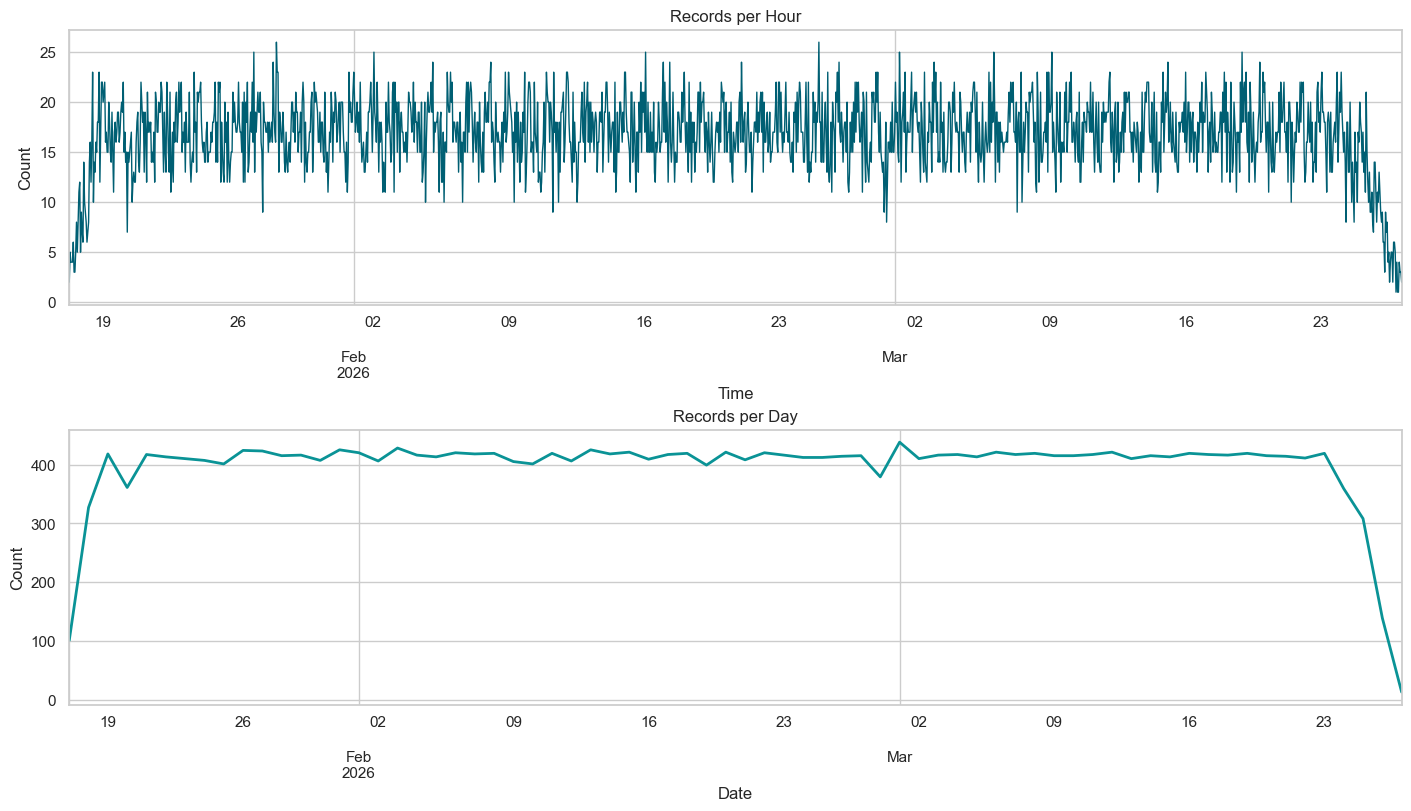

Hourly count summary:


,hourly_records
count,1654.000000
mean,16.775695
std,3.740346
min,1.000000
25%,15.000000
50%,17.000000
75%,19.000000
max,26.000000


Daily count summary:


,daily_records
count,70.000000
mean,396.385714
std,70.334870
min,13.000000
25%,409.250000
50%,415.000000
75%,419.000000
max,438.000000


Top 10 train_no by record count:


,records
train_no,
18237,5838
18238,5219
11077,4038
11078,3753
12137,3227
12138,2918
61632,1013
61631,970
11606,401


Sample records (post timestamp parsing/sorting):


,id,train_no,journey_date,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,delay_arrival_minutes,delay_departure_minutes,scheduled_arrival_ist,scheduled_departure_ist,actual_arrival_ist,actual_departure_ist,_event_time
0,1,61631,2026-01-17,BPL,1768615200,1.768615e+09,NaN,1.768616e+09,NaN,10.0,2026-01-17 07:30:00+05:30,2026-01-17 07:30:00+05:30,NaT,2026-01-17 07:40:20+05:30,2026-01-17 07:40:20+05:30
1,2,61631,2026-01-17,SUW,1768616040,1.768616e+09,1.768616e+09,1.768617e+09,6.0,11.0,2026-01-17 07:44:00+05:30,2026-01-17 07:45:00+05:30,2026-01-17 07:49:39+05:30,2026-01-17 07:56:15+05:30,2026-01-17 07:56:15+05:30
2,3,61631,2026-01-17,BVB,1768616640,1.768617e+09,NaN,1.768617e+09,NaN,6.0,2026-01-17 07:54:00+05:30,2026-01-17 07:55:00+05:30,NaT,2026-01-17 08:01:00+05:30,2026-01-17 08:01:00+05:30
3,4,61631,2026-01-17,DWG,1768617180,1.768617e+09,1.768618e+09,1.768618e+09,7.0,10.0,2026-01-17 08:03:00+05:30,2026-01-17 08:04:00+05:30,2026-01-17 08:10:22+05:30,2026-01-17 08:14:10+05:30,2026-01-17 08:14:10+05:30
4,5,61631,2026-01-17,SMT,1768617720,1.768618e+09,1.768618e+09,1.768618e+09,10.0,12.0,2026-01-17 08:12:00+05:30,2026-01-17 08:13:00+05:30,2026-01-17 08:21:54+05:30,2026-01-17 08:24:52+05:30,2026-01-17 08:24:52+05:30
5,6,61631,2026-01-17,SCI,1768618140,1.768618e+09,1.768619e+09,1.768619e+09,12.0,14.0,2026-01-17 08:19:00+05:30,2026-01-17 08:21:00+05:30,2026-01-17 08:31:26+05:30,2026-01-17 08:35:17+05:30,2026-01-17 08:35:17+05:30
6,7,61631,2026-01-17,BHS,1768618800,1.768619e+09,1.768620e+09,1.768620e+09,14.0,17.0,2026-01-17 08:30:00+05:30,2026-01-17 08:32:00+05:30,2026-01-17 08:44:25+05:30,2026-01-17 08:49:12+05:30,2026-01-17 08:49:12+05:30
7,8,61631,2026-01-17,SUMR,1768619880,1.768620e+09,1.768621e+09,1.768621e+09,16.0,20.0,2026-01-17 08:48:00+05:30,2026-01-17 08:49:00+05:30,2026-01-17 09:03:50+05:30,2026-01-17 09:08:52+05:30,2026-01-17 09:08:52+05:30
8,9,61631,2026-01-17,GLG,1768620360,1.768620e+09,1.768621e+09,1.768622e+09,18.0,20.0,2026-01-17 08:56:00+05:30,2026-01-17 08:58:00+05:30,2026-01-17 09:14:19+05:30,2026-01-17 09:18:24+05:30,2026-01-17 09:18:24+05:30
9,10,61631,2026-01-17,PAI,1768621080,1.768621e+09,1.768623e+09,1.768623e+09,26.0,31.0,2026-01-17 09:08:00+05:30,2026-01-17 09:09:00+05:30,2026-01-17 09:34:27+05:30,2026-01-17 09:39:49+05:30,2026-01-17 09:39:49+05:30


In [4]:
# 3) Initial EDA for time series behavior
# Aggregate record counts by hour/day to inspect data density.
hourly_counts = (
    df.set_index("_event_time")
      .resample("1h")
      .size()
      .rename("records")
)

daily_counts = (
    df.set_index("_event_time")
      .resample("1D")
      .size()
      .rename("records")
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)

hourly_counts.plot(ax=axes[0], color="#005f73", linewidth=1)
axes[0].set_title("Records per Hour")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Count")

daily_counts.plot(ax=axes[1], color="#0a9396", linewidth=2)
axes[1].set_title("Records per Day")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Count")

plt.show()

print("Hourly count summary:")
display(hourly_counts.describe().to_frame("hourly_records"))

print("Daily count summary:")
display(daily_counts.describe().to_frame("daily_records"))

# Optional: If key identifiers exist, quickly inspect top entities.
possible_id_cols = ["train_no", "train_id", "journey_id", "trip_id", "vehicle_id", "train_number"]
available_id_cols = [c for c in possible_id_cols if c in df.columns]

if available_id_cols:
    id_col = available_id_cols[0]
    print(f"Top 10 {id_col} by record count:")
    display(df[id_col].value_counts().head(10).to_frame("records"))
else:
    print("No standard train/journey identifier column found for top-entity analysis.")

print("Sample records (post timestamp parsing/sorting):")
display(df.head(15))

## Train 12138 - Weekly Station vs Departure Delay

Overlay departure-delay curves for each journey date in one week, using station sequence on x-axis.

Raw CSV row check:


,id,train_no,journey_date,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,delay_arrival_minutes,delay_departure_minutes
28613,28615,12138,2026-03-20,MAUR,1774032540,1.774033e+09,1.774033e+09,1.774033e+09,4.0,8.0


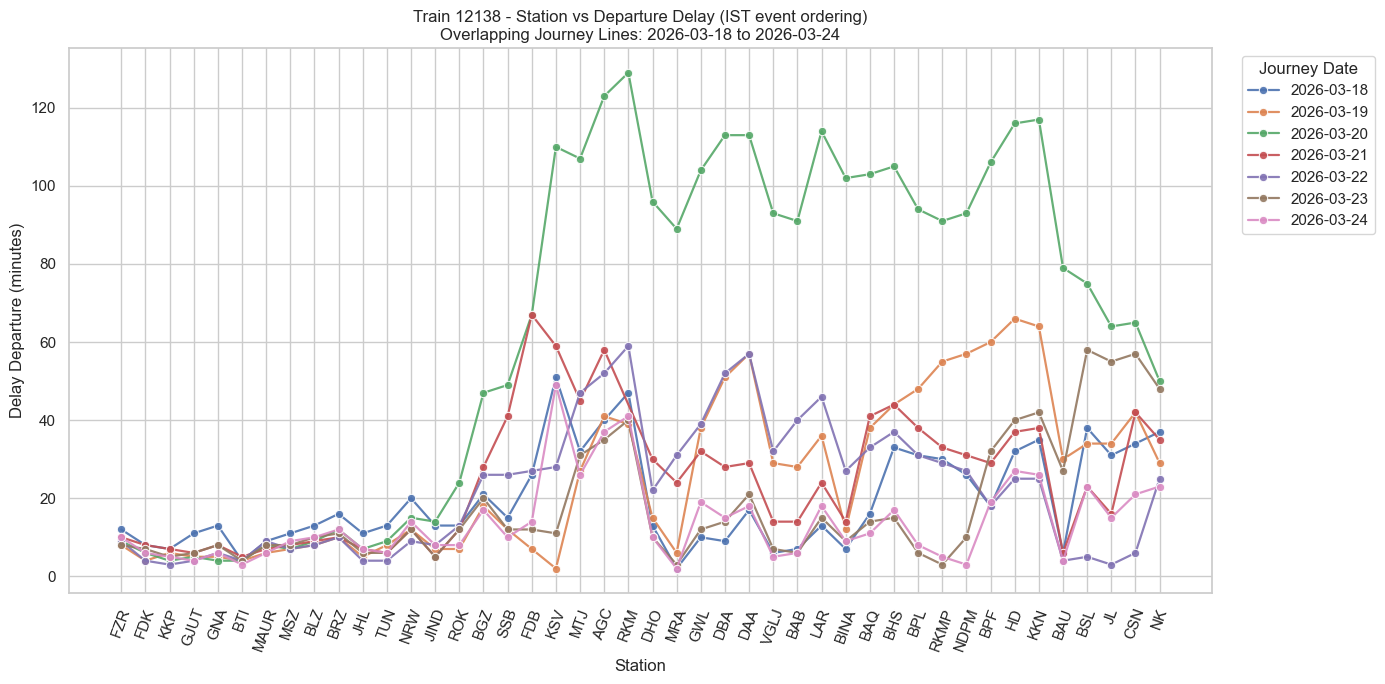

Plotted week: 2026-03-18 to 2026-03-24
Journeys in plot: 7
Stations in plot: 44

Debug check inside plotting frame (id=28615):


,journey_date,station_code,delay_departure_minutes,id
25690,2026-03-20,MAUR,8.0,28615


,journey_date,station_code,delay_departure_minutes,id
24807,2026-03-18,FZR,12.0,27689
24822,2026-03-18,FDK,8.0,27690
24828,2026-03-18,KKP,7.0,27691
24835,2026-03-18,GJUT,11.0,27692
24839,2026-03-18,GNA,13.0,27693
24848,2026-03-18,BTI,4.0,27694
24860,2026-03-18,MAUR,9.0,27695
24867,2026-03-18,MSZ,11.0,27696
24872,2026-03-18,BLZ,13.0,27697
24877,2026-03-18,BRZ,16.0,27698


In [5]:
# Weekly overlapping lines: station_code vs delay_departure_minutes for train 12138
# Debug and fix: use journey_date from CSV as journey key (not event-date derived key).
train_no_target = 12138
debug_id = 28615

required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Debug against raw CSV row.
raw_df = pd.read_csv(DATA_PATH)
raw_debug = raw_df.loc[raw_df["id"] == debug_id, [
    "id", "train_no", "journey_date", "station_code",
    "scheduled_arrival", "scheduled_departure", "actual_arrival", "actual_departure",
    "delay_arrival_minutes", "delay_departure_minutes"
]]
print("Raw CSV row check:")
display(raw_debug)

plot_df = df[df["train_no"] == train_no_target].copy()
plot_df = plot_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

if plot_df.empty:
    raise ValueError(f"No rows available for train_no={train_no_target} after filtering.")

# Ensure journey_date is the true journey key from source data.
plot_df["journey_date"] = pd.to_datetime(plot_df["journey_date"], errors="coerce").dt.date
plot_df = plot_df.dropna(subset=["journey_date"])

# Pick latest 7 journey dates for this train.
latest_journey_date = plot_df["journey_date"].max()
week_start = latest_journey_date - pd.Timedelta(days=6)
week_mask = (plot_df["journey_date"] >= week_start) & (plot_df["journey_date"] <= latest_journey_date)
week_df = plot_df.loc[week_mask].copy()

if week_df.empty:
    raise ValueError("No records found in selected 7-day journey window for train 12138.")

# If duplicate station entries exist for same journey, keep the latest record by id.
week_df = week_df.sort_values(["journey_date", "station_code", "id"])
week_df = week_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

# Use median event-time order per station as x-axis ordering for consistent overlap.
station_order = (
    week_df.groupby("station_code")["_event_time"]
    .median()
    .sort_values()
    .index
    .tolist()
)

week_df["station_code"] = pd.Categorical(week_df["station_code"], categories=station_order, ordered=True)
journey_station_delay = week_df.sort_values(["journey_date", "station_code"])[
    ["journey_date", "station_code", "delay_departure_minutes", "id"]
].copy()

plt.figure(figsize=(14, 7))
sns.lineplot(
    data=journey_station_delay,
    x="station_code",
    y="delay_departure_minutes",
    hue="journey_date",
    marker="o",
    linewidth=1.6,
    alpha=0.9,
)

plt.title(
    f"Train {train_no_target} - Station vs Departure Delay (IST event ordering)\n"
    f"Overlapping Journey Lines: {week_start} to {latest_journey_date}"
)
plt.xlabel("Station")
plt.ylabel("Delay Departure (minutes)")
plt.xticks(rotation=70)
plt.legend(title="Journey Date", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Plotted week: {week_start} to {latest_journey_date}")
print(f"Journeys in plot: {journey_station_delay['journey_date'].nunique()}")
print(f"Stations in plot: {journey_station_delay['station_code'].nunique()}")

print("\nDebug check inside plotting frame (id=28615):")
display(journey_station_delay.loc[journey_station_delay["id"] == debug_id])

display(journey_station_delay.head(20))

## Train 12138 - Monthly Interactive Station Delay View

Interactive Plotly chart for a 30-day window with one trace per journey date (legend toggle enabled).

In [6]:
# Monthly interactive lines (30-day window): station_code vs delay_departure_minutes for train 12138
import json
import plotly.express as px

TRAIN_NAME_MAP = {
    11077: "Jhelum Express (PT) (11077)",
    11078: "Jhelum Express (11078)",
    11605: "Bhopal - Bina MEMU Express (UnReserved) (11605)",
    11606: "Bina - Bhopal MEMU Express (UnReserved) (11606)",
    12137: "Punjab Mail (PT) (12137)",
    12138: "Punjab Mail (12138)",
    18237: "Chhattisgarh Express (PT) (18237)",
    18238: "Chhattisgarh Express (PT) (18238)",
    61631: "Bhopal - Bina MEMU (61631)",
    61632: "Bina - Bhopal MEMU (61632)",
}

train_no_target = 12138
train_name = TRAIN_NAME_MAP.get(train_no_target, f"Train {train_no_target}")
required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Reference halt sequence from static train route JSON.
STATIC_ROUTE_PATH = Path("../docs/statics/12138_static.json")
if not STATIC_ROUTE_PATH.exists():
    raise FileNotFoundError(f"Static route file not found: {STATIC_ROUTE_PATH.resolve()}")

with open(STATIC_ROUTE_PATH, "r", encoding="utf-8") as f:
    static_json = json.load(f)

route_rows = static_json.get("data", {}).get("route", [])
halt_route = [r for r in route_rows if int(r.get("isHalt", 0)) == 1]
halt_station_order_full = [r.get("stationCode") for r in sorted(halt_route, key=lambda x: x.get("sequence", 10**9)) if r.get("stationCode")]

if not halt_station_order_full:
    raise ValueError("No halt stations found in static route JSON.")

month_df = df[df["train_no"] == train_no_target].copy()
month_df = month_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

if month_df.empty:
    raise ValueError(f"No rows available for train_no={train_no_target} after filtering.")

# Keep journey_date from source as the true journey key.
month_df["journey_date"] = pd.to_datetime(month_df["journey_date"], errors="coerce").dt.date
month_df = month_df.dropna(subset=["journey_date"])

latest_journey_date = month_df["journey_date"].max()
month_start = latest_journey_date - pd.Timedelta(days=29)
month_mask = (month_df["journey_date"] >= month_start) & (month_df["journey_date"] <= latest_journey_date)
month_df = month_df.loc[month_mask].copy()

if month_df.empty:
    raise ValueError("No records found in selected 30-day journey window for train 12138.")

# Ignore intermediate stations (isHalt=0) by keeping only halt stations from static route.
month_df = month_df[month_df["station_code"].isin(halt_station_order_full)].copy()

if month_df.empty:
    raise ValueError("No halt-station records available in the selected month window.")

# Keep latest row for duplicate journey_date + station_code combinations.
month_df = month_df.sort_values(["journey_date", "station_code", "id"])
month_df = month_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

present_halts = set(month_df["station_code"].unique())
station_order = halt_station_order_full.copy()
missing_halts_in_month = [s for s in halt_station_order_full if s not in present_halts]

# Build a full journey_date x halt-station grid so all halt stations remain on axis.
journey_dates_sorted = sorted(month_df["journey_date"].unique())
full_index = pd.MultiIndex.from_product(
    [journey_dates_sorted, station_order],
    names=["journey_date", "station_code"],
)
month_plot = (
    month_df.set_index(["journey_date", "station_code"])[["delay_departure_minutes", "id"]]
    .reindex(full_index)
    .reset_index()
)
month_plot["station_code"] = pd.Categorical(month_plot["station_code"], categories=station_order, ordered=True)
month_plot = month_plot.sort_values(["journey_date", "station_code"])
month_plot["journey_date"] = month_plot["journey_date"].astype(str)

fig = px.line(
    month_plot,
    x="station_code",
    y="delay_departure_minutes",
    color="journey_date",
    markers=True,
    category_orders={"station_code": station_order},
    title=(
        f"{train_name} - Halt Station vs Departure Delay (30 Days)"
        f"<br><sup>Journey dates: {month_start} to {latest_journey_date}</sup>"
    ),
    labels={
        "station_code": "Station (halt-only, static route order)",
        "delay_departure_minutes": "Delay Departure (minutes)",
        "journey_date": "Journey Date",
    },
    hover_data={"id": True},
)

fig.update_layout(
    template="plotly_white",
    height=650,
    legend_title_text="Journey Date (click to toggle)",
)
fig.update_xaxes(
    tickangle=70,
    categoryorder="array",
    categoryarray=station_order,
    tickmode="array",
    tickvals=station_order,
    ticktext=station_order,
)
fig.show()

print(f"Train: {train_name}")
print(f"Plotted month: {month_start} to {latest_journey_date}")
print(f"Journeys in plot: {month_plot['journey_date'].nunique()}")
print(f"Halt stations plotted: {len(station_order)} / {len(halt_station_order_full)} in static route")
print(f"Missing halt stations with no data in selected month window: {len(missing_halts_in_month)}")
if missing_halts_in_month:
    print(missing_halts_in_month)

display(month_plot.head(20))

Train: Punjab Mail (12138)
Plotted month: 2026-02-23 to 2026-03-24
Journeys in plot: 30
Halt stations plotted: 52 / 52 in static route
Missing halt stations with no data in selected month window: 8
['DKZ', 'NDLS', 'ET', 'KNW', 'MMR', 'KYN', 'DR', 'CSMT']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-23,FZR,9.0,17125.0
1,2026-02-23,FDK,7.0,17126.0
2,2026-02-23,KKP,9.0,17127.0
3,2026-02-23,GJUT,10.0,17128.0
4,2026-02-23,GNA,13.0,17129.0
5,2026-02-23,BTI,4.0,17130.0
6,2026-02-23,MAUR,10.0,17131.0
7,2026-02-23,MSZ,11.0,17132.0
8,2026-02-23,BLZ,12.0,17133.0
9,2026-02-23,BRZ,13.0,17134.0


In [7]:
# Train 61632 - Monthly interactive halt-only station delay view
import json
import plotly.express as px

TRAIN_NAME_MAP = {
    11077: "Jhelum Express (PT) (11077)",
    11078: "Jhelum Express (11078)",
    11605: "Bhopal - Bina MEMU Express (UnReserved) (11605)",
    11606: "Bina - Bhopal MEMU Express (UnReserved) (11606)",
    12137: "Punjab Mail (PT) (12137)",
    12138: "Punjab Mail (12138)",
    18237: "Chhattisgarh Express (PT) (18237)",
    18238: "Chhattisgarh Express (PT) (18238)",
    61631: "Bhopal - Bina MEMU (61631)",
    61632: "Bina - Bhopal MEMU (61632)",
}

train_no_target = 61632
train_name = TRAIN_NAME_MAP.get(train_no_target, f"Train {train_no_target}")
required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Halt-only sequence from static route JSON for 61632.
STATIC_ROUTE_PATH = Path("../docs/statics/61632_static.json")
if not STATIC_ROUTE_PATH.exists():
    raise FileNotFoundError(f"Static route file not found: {STATIC_ROUTE_PATH.resolve()}")

with open(STATIC_ROUTE_PATH, "r", encoding="utf-8") as f:
    static_json = json.load(f)

route_rows = static_json.get("data", {}).get("route", [])
halt_route = [r for r in route_rows if int(r.get("isHalt", 0)) == 1]
halt_station_order_full = [
    r.get("stationCode")
    for r in sorted(halt_route, key=lambda x: x.get("sequence", 10**9))
    if r.get("stationCode")
]

if not halt_station_order_full:
    raise ValueError("No halt stations found in static route JSON for 61632.")

month_df = df[df["train_no"] == train_no_target].copy()
month_df = month_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

if month_df.empty:
    raise ValueError(f"No rows available for train_no={train_no_target} after filtering.")

month_df["journey_date"] = pd.to_datetime(month_df["journey_date"], errors="coerce").dt.date
month_df = month_df.dropna(subset=["journey_date"])

latest_journey_date = month_df["journey_date"].max()
month_start = latest_journey_date - pd.Timedelta(days=29)
month_mask = (month_df["journey_date"] >= month_start) & (month_df["journey_date"] <= latest_journey_date)
month_df = month_df.loc[month_mask].copy()

if month_df.empty:
    raise ValueError("No records found in selected 30-day journey window for train 61632.")

# Ignore intermediate stations (isHalt=0).
month_df = month_df[month_df["station_code"].isin(halt_station_order_full)].copy()

if month_df.empty:
    raise ValueError("No halt-station records available in selected month window for 61632.")

# Keep latest row for duplicate journey_date + station_code combinations.
month_df = month_df.sort_values(["journey_date", "station_code", "id"])
month_df = month_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

present_halts = set(month_df["station_code"].unique())
station_order = halt_station_order_full.copy()
missing_halts_in_month = [s for s in halt_station_order_full if s not in present_halts]

# Build a full journey_date x halt-station grid so all halt stations remain on axis.
journey_dates_sorted = sorted(month_df["journey_date"].unique())
full_index = pd.MultiIndex.from_product(
    [journey_dates_sorted, station_order],
    names=["journey_date", "station_code"],
)
month_plot = (
    month_df.set_index(["journey_date", "station_code"])[["delay_departure_minutes", "id"]]
    .reindex(full_index)
    .reset_index()
)
month_plot["station_code"] = pd.Categorical(month_plot["station_code"], categories=station_order, ordered=True)
month_plot = month_plot.sort_values(["journey_date", "station_code"])
month_plot["journey_date"] = month_plot["journey_date"].astype(str)

fig = px.line(
    month_plot,
    x="station_code",
    y="delay_departure_minutes",
    color="journey_date",
    markers=True,
    category_orders={"station_code": station_order},
    title=(
        f"{train_name} - Halt Station vs Departure Delay (30 Days)"
        f"<br><sup>Journey dates: {month_start} to {latest_journey_date}</sup>"
    ),
    labels={
        "station_code": "Station (halt-only, static route order)",
        "delay_departure_minutes": "Delay Departure (minutes)",
        "journey_date": "Journey Date",
    },
    hover_data={"id": True},
)

fig.update_layout(
    template="plotly_white",
    height=650,
    legend_title_text="Journey Date (click to toggle)",
)
fig.update_xaxes(
    tickangle=70,
    categoryorder="array",
    categoryarray=station_order,
    tickmode="array",
    tickvals=station_order,
    ticktext=station_order,
)
fig.show()

print(f"Train: {train_name}")
print(f"Plotted month: {month_start} to {latest_journey_date}")
print(f"Journeys in plot: {month_plot['journey_date'].nunique()}")
print(f"Halt stations plotted: {len(station_order)} / {len(halt_station_order_full)} in static route")
print(f"Missing halt stations with no data in selected month window: {len(missing_halts_in_month)}")
if missing_halts_in_month:
    print(missing_halts_in_month)

display(month_plot.head(20))

Train: Bina - Bhopal MEMU (61632)
Plotted month: 2026-02-25 to 2026-03-26
Journeys in plot: 30
Halt stations plotted: 16 / 16 in static route
Missing halt stations with no data in selected month window: 1
['BPL']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-25,BINA,6.0,17492.0
1,2026-02-25,KIKA,2.0,17493.0
2,2026-02-25,MABA,6.0,17494.0
3,2026-02-25,KAH,3.0,17495.0
4,2026-02-25,BET,5.0,17496.0
5,2026-02-25,BAQ,17.0,17497.0
6,2026-02-25,PAI,18.0,17498.0
7,2026-02-25,GLG,18.0,17499.0
8,2026-02-25,SUMR,17.0,17500.0
9,2026-02-25,BHS,25.0,17501.0


## Monthly Interactive Plots - Remaining 8 Trains

Creates 30-day halt-only station delay plots (legend-toggle enabled) for all remaining trains using static route sequence from `docs/statics/*_static.json`.

In [8]:
# 30-day halt-only Plotly charts for remaining 8 trains in train_info set
import json
import plotly.express as px

TRAIN_NAME_MAP = {
    11077: "Jhelum Express (PT) (11077)",
    11078: "Jhelum Express (11078)",
    11605: "Bhopal - Bina MEMU Express (UnReserved) (11605)",
    11606: "Bina - Bhopal MEMU Express (UnReserved) (11606)",
    12137: "Punjab Mail (PT) (12137)",
    12138: "Punjab Mail (12138)",
    18237: "Chhattisgarh Express (PT) (18237)",
    18238: "Chhattisgarh Express (PT) (18238)",
    61631: "Bhopal - Bina MEMU (61631)",
    61632: "Bina - Bhopal MEMU (61632)",
}

remaining_trains = [61631, 11605, 11606, 12137, 11077, 11078, 18237, 18238]

required_cols = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

for train_no_target in remaining_trains:
    train_name = TRAIN_NAME_MAP.get(train_no_target, f"Train {train_no_target}")
    static_path = Path(f"../docs/statics/{train_no_target}_static.json")
    if not static_path.exists():
        print(f"\n[SKIP] {train_no_target}: static file not found at {static_path}")
        continue

    with open(static_path, "r", encoding="utf-8") as f:
        static_json = json.load(f)

    route_rows = static_json.get("data", {}).get("route", [])
    halt_route = [r for r in route_rows if int(r.get("isHalt", 0)) == 1]
    halt_station_order_full = [
        r.get("stationCode")
        for r in sorted(halt_route, key=lambda x: x.get("sequence", 10**9))
        if r.get("stationCode")
    ]

    if not halt_station_order_full:
        print(f"\n[SKIP] {train_no_target}: no halt stations in static JSON")
        continue

    month_df = df[df["train_no"] == train_no_target].copy()
    month_df = month_df.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])

    if month_df.empty:
        print(f"\n[SKIP] {train_no_target}: no rows after filtering")
        continue

    month_df["journey_date"] = pd.to_datetime(month_df["journey_date"], errors="coerce").dt.date
    month_df = month_df.dropna(subset=["journey_date"])

    latest_journey_date = month_df["journey_date"].max()
    month_start = latest_journey_date - pd.Timedelta(days=29)
    month_mask = (month_df["journey_date"] >= month_start) & (month_df["journey_date"] <= latest_journey_date)
    month_df = month_df.loc[month_mask].copy()

    if month_df.empty:
        print(f"\n[SKIP] {train_no_target}: no records in selected 30-day window")
        continue

    # Keep halt-only stations using static route reference.
    month_df = month_df[month_df["station_code"].isin(halt_station_order_full)].copy()

    if month_df.empty:
        print(f"\n[SKIP] {train_no_target}: no halt-station rows in selected window")
        continue

    # Keep latest row for duplicate journey_date + station_code combinations.
    month_df = month_df.sort_values(["journey_date", "station_code", "id"])
    month_df = month_df.drop_duplicates(subset=["journey_date", "station_code"], keep="last")

    present_halts = set(month_df["station_code"].unique())
    station_order = halt_station_order_full.copy()
    missing_halts_in_month = [s for s in halt_station_order_full if s not in present_halts]

    # Build a full journey_date x halt-station grid so all halt stations remain on axis.
    journey_dates_sorted = sorted(month_df["journey_date"].unique())
    full_index = pd.MultiIndex.from_product(
        [journey_dates_sorted, station_order],
        names=["journey_date", "station_code"],
    )
    month_plot = (
        month_df.set_index(["journey_date", "station_code"])[["delay_departure_minutes", "id"]]
        .reindex(full_index)
        .reset_index()
    )
    month_plot["station_code"] = pd.Categorical(month_plot["station_code"], categories=station_order, ordered=True)
    month_plot = month_plot.sort_values(["journey_date", "station_code"])
    month_plot["journey_date"] = month_plot["journey_date"].astype(str)

    fig = px.line(
        month_plot,
        x="station_code",
        y="delay_departure_minutes",
        color="journey_date",
        markers=True,
        category_orders={"station_code": station_order},
        title=(
            f"{train_name} - Halt Station vs Departure Delay (30 Days)"
            f"<br><sup>Journey dates: {month_start} to {latest_journey_date}</sup>"
        ),
        labels={
            "station_code": "Station (halt-only, static route order)",
            "delay_departure_minutes": "Delay Departure (minutes)",
            "journey_date": "Journey Date",
        },
        hover_data={"id": True},
    )

    fig.update_layout(
        template="plotly_white",
        height=650,
        legend_title_text="Journey Date (click to toggle)",
    )
    fig.update_xaxes(
        tickangle=70,
        categoryorder="array",
        categoryarray=station_order,
        tickmode="array",
        tickvals=station_order,
        ticktext=station_order,
    )
    fig.show()

    print(f"\nTrain: {train_name}")
    print(f"Plotted month: {month_start} to {latest_journey_date}")
    print(f"Journeys in plot: {month_plot['journey_date'].nunique()}")
    print(f"Halt stations plotted: {len(station_order)} / {len(halt_station_order_full)}")
    print(f"Missing halt stations with no data in selected month window: {len(missing_halts_in_month)}")
    if missing_halts_in_month:
        print(missing_halts_in_month)

    display(month_plot.head(10))


Train: Bhopal - Bina MEMU (61631)
Plotted month: 2026-02-25 to 2026-03-26
Journeys in plot: 29
Halt stations plotted: 16 / 16
Missing halt stations with no data in selected month window: 1
['BINA']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-25,BPL,NaN,NaN
1,2026-02-25,SUW,11.0,17103.0
2,2026-02-25,BVB,8.0,17104.0
3,2026-02-25,DWG,12.0,17105.0
4,2026-02-25,SMT,21.0,17106.0
5,2026-02-25,SCI,25.0,17107.0
6,2026-02-25,BHS,27.0,17108.0
7,2026-02-25,SUMR,24.0,17109.0
8,2026-02-25,GLG,31.0,17110.0
9,2026-02-25,PAI,31.0,17111.0



Train: Bhopal - Bina MEMU Express (UnReserved) (11605)
Plotted month: 2026-02-25 to 2026-03-26
Journeys in plot: 30
Halt stations plotted: 7 / 7
Missing halt stations with no data in selected month window: 1
['BINA']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-25,BPL,NaN,NaN
1,2026-02-25,SCI,29.0,17486.0
2,2026-02-25,BHS,34.0,17487.0
3,2026-02-25,GLG,36.0,17488.0
4,2026-02-25,BAQ,38.0,17489.0
5,2026-02-25,MABA,33.0,17490.0
6,2026-02-25,BINA,NaN,NaN
7,2026-02-26,BPL,NaN,NaN
8,2026-02-26,SCI,31.0,17946.0
9,2026-02-26,BHS,33.0,17947.0



Train: Bina - Bhopal MEMU Express (UnReserved) (11606)
Plotted month: 2026-02-25 to 2026-03-26
Journeys in plot: 30
Halt stations plotted: 7 / 7
Missing halt stations with no data in selected month window: 1
['BPL']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-25,BINA,7.0,17118.0
1,2026-02-25,MABA,0.0,17119.0
2,2026-02-25,BAQ,8.0,17120.0
3,2026-02-25,GLG,11.0,17121.0
4,2026-02-25,BHS,20.0,17122.0
5,2026-02-25,SCI,18.0,17123.0
6,2026-02-25,BPL,NaN,NaN
7,2026-02-26,BINA,21.0,17578.0
8,2026-02-26,MABA,25.0,17579.0
9,2026-02-26,BAQ,26.0,17580.0


... (6 outputs left out)


Train: Chhattisgarh Express (PT) (18237)
Plotted month: 2026-02-23 to 2026-03-24
Journeys in plot: 30
Halt stations plotted: 92 / 92
Missing halt stations with no data in selected month window: 3
['AMLA', 'ET', 'ASR']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-23,KRBA,21.0,17308.0
1,2026-02-23,URGA,20.0,17309.0
2,2026-02-23,SRBA,22.0,17310.0
3,2026-02-23,MWRN,24.0,17311.0
4,2026-02-23,KTHD,24.0,17312.0
5,2026-02-23,BPRH,23.0,17313.0
6,2026-02-23,CPH,24.0,17314.0
7,2026-02-23,NIA,35.0,17315.0
8,2026-02-23,AKT,35.0,17316.0
9,2026-02-23,JRMG,34.0,17317.0



Train: Chhattisgarh Express (PT) (18238)
Plotted month: 2026-02-22 to 2026-03-23
Journeys in plot: 30
Halt stations plotted: 85 / 85
Missing halt stations with no data in selected month window: 5
['YJUD', 'ET', 'DURG', 'HN', 'BSP']


,journey_date,station_code,delay_departure_minutes,id
0,2026-02-22,ASR,10.0,16875.0
1,2026-02-22,JNL,18.0,16876.0
2,2026-02-22,BEAS,22.0,16877.0
3,2026-02-22,JUC,16.0,16878.0
4,2026-02-22,JRC,4.0,16879.0
5,2026-02-22,PGW,7.0,16880.0
6,2026-02-22,PHR,6.0,16881.0
7,2026-02-22,LDH,20.0,16882.0
8,2026-02-22,SNL,3.0,16883.0
9,2026-02-22,DOA,6.0,16884.0


## Train 18238 - Station Pair Alpha (Delay Added vs Cover-up)

This section quantifies where delay is systematically added or recovered between adjacent halt stations for train 18238.

Definitions:
- Pair delta for one journey = delay_departure_minutes(station_to) - delay_departure_minutes(station_from)
- Alpha median = robust typical pair delta across journeys
- Alpha mean = average pair delta across journeys (sensitivity to spikes)

Interpretation:
- Positive alpha: delay accumulation zone (train loses time)
- Negative alpha: cover-up zone (train recovers time)
- Practical significance threshold: absolute alpha >= 1 minute

In [9]:
# Compute adjacent halt-pair alpha metrics for train 18238 (median and mean)
import json

train_no_alpha = 18238
alpha_threshold_min = 1.0

required_cols_alpha = ["id", "train_no", "journey_date", "station_code", "delay_departure_minutes", "_event_time"]
missing_required_alpha = [c for c in required_cols_alpha if c not in df.columns]
if missing_required_alpha:
    raise KeyError(f"Missing required columns for alpha analysis: {missing_required_alpha}")

static_path_alpha = Path(f"../docs/statics/{train_no_alpha}_static.json")
if not static_path_alpha.exists():
    raise FileNotFoundError(f"Static route file not found: {static_path_alpha.resolve()}")

with open(static_path_alpha, "r", encoding="utf-8") as f:
    static_json_alpha = json.load(f)

route_rows_alpha = static_json_alpha.get("data", {}).get("route", [])
halt_route_alpha = [r for r in route_rows_alpha if int(r.get("isHalt", 0)) == 1]
halt_station_order_alpha = [
    r.get("stationCode")
    for r in sorted(halt_route_alpha, key=lambda x: x.get("sequence", 10**9))
    if r.get("stationCode")
]

if len(halt_station_order_alpha) < 2:
    raise ValueError("Need at least two halt stations in static route to compute station-pair alpha.")

seq_map_alpha = {s: i + 1 for i, s in enumerate(halt_station_order_alpha)}

# Rebuild 30-day frame for 18238 using same monthly plotting policy.
month_df_18238 = df[df["train_no"] == train_no_alpha].copy()
month_df_18238 = month_df_18238.dropna(subset=["delay_departure_minutes", "station_code", "_event_time", "journey_date"])
if month_df_18238.empty:
    raise ValueError("No rows for 18238 after required-column filtering.")

month_df_18238["journey_date"] = pd.to_datetime(month_df_18238["journey_date"], errors="coerce").dt.date
month_df_18238 = month_df_18238.dropna(subset=["journey_date"])

latest_journey_date_18238 = month_df_18238["journey_date"].max()
month_start_18238 = latest_journey_date_18238 - pd.Timedelta(days=29)
mask_30d_18238 = (
    (month_df_18238["journey_date"] >= month_start_18238)
    & (month_df_18238["journey_date"] <= latest_journey_date_18238)
)
month_df_18238 = month_df_18238.loc[mask_30d_18238].copy()

month_df_18238 = month_df_18238[month_df_18238["station_code"].isin(halt_station_order_alpha)].copy()
if month_df_18238.empty:
    raise ValueError("No halt-station rows for 18238 in selected 30-day window.")

# Keep the latest poll snapshot per journey-date and station.
month_df_18238 = month_df_18238.sort_values(["journey_date", "station_code", "id"])
month_df_18238 = month_df_18238.drop_duplicates(subset=["journey_date", "station_code"], keep="last")
month_df_18238["seq"] = month_df_18238["station_code"].map(seq_map_alpha)
month_df_18238 = month_df_18238.dropna(subset=["seq"]).copy()
month_df_18238["seq"] = month_df_18238["seq"].astype(int)

# Build adjacent-pair deltas per journey; skip missing station values for a pair.
pair_rows = []
for journey_date_value, g in month_df_18238.groupby("journey_date"):
    gg = g.sort_values("seq")[["station_code", "seq", "delay_departure_minutes"]].copy()
    gg["station_to"] = gg["station_code"].shift(-1)
    gg["seq_to"] = gg["seq"].shift(-1)
    gg["delay_to"] = gg["delay_departure_minutes"].shift(-1)
    gg = gg.dropna(subset=["station_to", "delay_departure_minutes", "delay_to"])  # pair-level skip policy

    # Keep only truly adjacent static-route pairs.
    gg = gg[(gg["seq_to"] - gg["seq"]) == 1].copy()
    if gg.empty:
        continue

    gg["delta_delay_min"] = gg["delay_to"] - gg["delay_departure_minutes"]
    for _, row in gg.iterrows():
        pair_rows.append(
            {
                "journey_date": journey_date_value,
                "station_from": row["station_code"],
                "station_to": row["station_to"],
                "seq_from": int(row["seq"]),
                "seq_to": int(row["seq_to"]),
                "delay_from_min": float(row["delay_departure_minutes"]),
                "delay_to_min": float(row["delay_to"]),
                "delta_delay_min": float(row["delta_delay_min"]),
            }
        )

df_pairs_18238 = pd.DataFrame(pair_rows)
if df_pairs_18238.empty:
    raise ValueError("No valid adjacent station-pair deltas found for 18238.")

def _mad(values: pd.Series) -> float:
    med = float(values.median())
    return float((values - med).abs().median())

alpha_pair_stats_18238 = (
    df_pairs_18238.groupby(["station_from", "station_to", "seq_from", "seq_to"], as_index=False)
    .agg(
        n_journeys=("delta_delay_min", "size"),
        alpha_median_min=("delta_delay_min", "median"),
        alpha_mean_min=("delta_delay_min", "mean"),
        alpha_std_min=("delta_delay_min", "std"),
        alpha_q25_min=("delta_delay_min", lambda s: s.quantile(0.25)),
        alpha_q75_min=("delta_delay_min", lambda s: s.quantile(0.75)),
        alpha_min=("delta_delay_min", "min"),
        alpha_max=("delta_delay_min", "max"),
        alpha_mad_min=("delta_delay_min", _mad),
    )
)

alpha_pair_stats_18238["alpha_iqr_min"] = (
    alpha_pair_stats_18238["alpha_q75_min"] - alpha_pair_stats_18238["alpha_q25_min"]
)
alpha_pair_stats_18238["pair_label"] = (
    alpha_pair_stats_18238["station_from"] + " -> " + alpha_pair_stats_18238["station_to"]
)

alpha_pair_stats_18238["median_zone"] = np.select(
    [
        alpha_pair_stats_18238["alpha_median_min"] >= alpha_threshold_min,
        alpha_pair_stats_18238["alpha_median_min"] <= -alpha_threshold_min,
    ],
    ["adds_delay", "covers_up"],
    default="neutral",
)
alpha_pair_stats_18238["mean_zone"] = np.select(
    [
        alpha_pair_stats_18238["alpha_mean_min"] >= alpha_threshold_min,
        alpha_pair_stats_18238["alpha_mean_min"] <= -alpha_threshold_min,
    ],
    ["adds_delay", "covers_up"],
    default="neutral",
)

# Static-route adjacent pair template (for coverage diagnostics only).
adj_template_18238 = pd.DataFrame(
    {
        "station_from": halt_station_order_alpha[:-1],
        "station_to": halt_station_order_alpha[1:],
        "seq_from": np.arange(1, len(halt_station_order_alpha)),
        "seq_to": np.arange(2, len(halt_station_order_alpha) + 1),
    }
)
adj_template_18238["pair_label"] = adj_template_18238["station_from"] + " -> " + adj_template_18238["station_to"]

alpha_pair_stats_full_18238 = adj_template_18238.merge(
    alpha_pair_stats_18238,
    on=["station_from", "station_to", "seq_from", "seq_to", "pair_label"],
    how="left",
)

journey_count_18238 = month_df_18238["journey_date"].nunique()
alpha_pair_stats_full_18238["coverage_ratio"] = (
    alpha_pair_stats_full_18238["n_journeys"] / journey_count_18238
)

print(f"Train: {train_no_alpha}")
print(f"Window: {month_start_18238} to {latest_journey_date_18238} ({journey_count_18238} journey dates)")
print(f"Halt stations in static route: {len(halt_station_order_alpha)}")
print(f"Expected adjacent pairs: {len(halt_station_order_alpha) - 1}")
print(f"Pairs with at least 1 observation: {alpha_pair_stats_18238.shape[0]}")

display(alpha_pair_stats_full_18238.head(20))

Train: 18238
Window: 2026-02-22 to 2026-03-23 (30 journey dates)
Halt stations in static route: 85
Expected adjacent pairs: 84
Pairs with at least 1 observation: 75


,station_from,station_to,seq_from,seq_to,pair_label,n_journeys,alpha_median_min,alpha_mean_min,alpha_std_min,alpha_q25_min,alpha_q75_min,alpha_min,alpha_max,alpha_mad_min,alpha_iqr_min,median_zone,mean_zone,coverage_ratio
0,ASR,JNL,1,2,ASR -> JNL,30.0,4.0,4.233333,2.062528,3.00,5.00,1.0,9.0,1.0,2.00,adds_delay,adds_delay,1.0
1,JNL,BEAS,2,3,JNL -> BEAS,30.0,3.0,5.200000,5.378117,3.00,5.00,0.0,26.0,1.0,2.00,adds_delay,adds_delay,1.0
2,BEAS,JUC,3,4,BEAS -> JUC,30.0,-6.0,-5.266667,6.617288,-10.75,-1.00,-14.0,7.0,5.0,9.75,covers_up,covers_up,1.0
3,JUC,JRC,4,5,JUC -> JRC,30.0,-10.5,-8.033333,5.991277,-13.00,-3.00,-15.0,7.0,3.5,10.00,covers_up,covers_up,1.0
4,JRC,PGW,5,6,JRC -> PGW,30.0,3.0,3.533333,2.192988,2.25,4.00,2.0,14.0,1.0,1.75,adds_delay,adds_delay,1.0
5,PGW,PHR,6,7,PGW -> PHR,30.0,-1.0,1.966667,8.680074,-1.00,0.00,-2.0,33.0,1.0,1.00,covers_up,adds_delay,1.0
6,PHR,LDH,7,8,PHR -> LDH,30.0,3.0,3.233333,5.709540,-1.00,5.00,-5.0,24.0,3.5,6.00,adds_delay,adds_delay,1.0
7,LDH,SNL,8,9,LDH -> SNL,30.0,-9.0,-10.500000,6.399084,-14.50,-7.00,-28.0,-1.0,3.5,7.50,covers_up,covers_up,1.0
8,SNL,DOA,9,10,SNL -> DOA,30.0,5.0,5.300000,4.450107,4.00,5.00,3.0,28.0,1.0,1.00,adds_delay,adds_delay,1.0
9,DOA,CHA,10,11,DOA -> CHA,30.0,3.0,2.633333,1.751518,2.00,4.00,-5.0,4.0,1.0,2.00,adds_delay,adds_delay,1.0


Alpha zones by median threshold (|alpha| >= 1 minute):
median_zone
adds_delay    42
covers_up     24
neutral        9
Name: count, dtype: int64

Alpha zones by mean threshold (|alpha| >= 1 minute):
mean_zone
adds_delay    47
covers_up     22
neutral        6
Name: count, dtype: int64

Top 10 delay-adding pairs by median alpha:


,pair_label,n_journeys,coverage_ratio,alpha_median_min,alpha_mean_min,alpha_iqr_min
34,MTJ -> RKM,30.0,1.000000,36.0,28.733333,39.75
72,BPHB -> R,26.0,0.866667,17.0,18.538462,11.50
37,DHO -> MRA,30.0,1.000000,14.5,26.266667,35.00
67,TRO -> G,30.0,1.000000,13.5,14.833333,15.00
33,CHJ -> MTJ,30.0,1.000000,11.5,14.200000,9.25
47,LAR -> DUA,30.0,1.000000,9.0,9.366667,7.50
54,RKMP -> ODG,30.0,1.000000,8.0,8.566667,1.75
35,RKM -> AGC,30.0,1.000000,7.0,8.600000,4.75
59,MTY -> PAR,30.0,1.000000,7.0,8.566667,7.50
70,SKS -> DGG,30.0,1.000000,6.5,9.133333,9.00


Top 10 cover-up pairs by median alpha:


,pair_label,n_journeys,coverage_ratio,alpha_median_min,alpha_mean_min,alpha_iqr_min
36,AGC -> DHO,30.0,1.0,-71.0,-57.166667,43.75
62,KATL -> NGP,30.0,1.0,-26.0,-27.800000,15.25
48,DUA -> BINA,30.0,1.0,-18.5,-19.166667,8.50
38,MRA -> GWL,30.0,1.0,-15.0,-23.633333,45.75
12,GVG -> SIR,30.0,1.0,-11.0,-10.900000,2.00
3,JUC -> JRC,30.0,1.0,-10.5,-8.033333,10.00
7,LDH -> SNL,30.0,1.0,-9.0,-10.500000,7.50
30,BVH -> PWL,30.0,1.0,-8.5,-6.933333,6.00
69,AGN -> SKS,30.0,1.0,-7.0,-6.133333,3.00
74,BYT -> BYL,30.0,1.0,-6.5,-4.733333,6.75


Top 10 delay-adding pairs by mean alpha:


,pair_label,n_journeys,coverage_ratio,alpha_median_min,alpha_mean_min,alpha_iqr_min
34,MTJ -> RKM,30.0,1.000000,36.0,28.733333,39.75
37,DHO -> MRA,30.0,1.000000,14.5,26.266667,35.00
72,BPHB -> R,26.0,0.866667,17.0,18.538462,11.50
17,RAA -> JUDW,30.0,1.000000,1.0,17.333333,17.00
67,TRO -> G,30.0,1.000000,13.5,14.833333,15.00
33,CHJ -> MTJ,30.0,1.000000,11.5,14.200000,9.25
71,DGG -> RJN,30.0,1.000000,6.0,9.466667,5.75
47,LAR -> DUA,30.0,1.000000,9.0,9.366667,7.50
70,SKS -> DGG,30.0,1.000000,6.5,9.133333,9.00
15,UBC -> UMB,30.0,1.000000,6.0,8.966667,9.75


Top 10 cover-up pairs by mean alpha:


,pair_label,n_journeys,coverage_ratio,alpha_median_min,alpha_mean_min,alpha_iqr_min
36,AGC -> DHO,30.0,1.0,-71.0,-57.166667,43.75
62,KATL -> NGP,30.0,1.0,-26.0,-27.800000,15.25
38,MRA -> GWL,30.0,1.0,-15.0,-23.633333,45.75
48,DUA -> BINA,30.0,1.0,-18.5,-19.166667,8.50
12,GVG -> SIR,30.0,1.0,-11.0,-10.900000,2.00
7,LDH -> SNL,30.0,1.0,-9.0,-10.500000,7.50
3,JUC -> JRC,30.0,1.0,-10.5,-8.033333,10.00
30,BVH -> PWL,30.0,1.0,-8.5,-6.933333,6.00
69,AGN -> SKS,30.0,1.0,-7.0,-6.133333,3.00
2,BEAS -> JUC,30.0,1.0,-6.0,-5.266667,9.75


Pairs with low journey coverage (< 50%):


,pair_label,n_journeys,coverage_ratio,alpha_median_min,alpha_mean_min,alpha_iqr_min
64,PAR -> NRKR,4.0,0.133333,1.0,0.75,0.75
65,NRKR -> KATL,4.0,0.133333,2.5,2.75,5.75
18,JUDW -> YJUD,NaN,NaN,NaN,NaN,NaN
19,YJUD -> SRE,NaN,NaN,NaN,NaN,NaN
58,NDPM -> ET,NaN,NaN,NaN,NaN,NaN
59,ET -> GDYA,NaN,NaN,NaN,NaN,NaN
76,RJN -> DURG,NaN,NaN,NaN,NaN,NaN
77,DURG -> BPHB,NaN,NaN,NaN,NaN,NaN
80,TLD -> HN,NaN,NaN,NaN,NaN,NaN
81,HN -> BYT,NaN,NaN,NaN,NaN,NaN


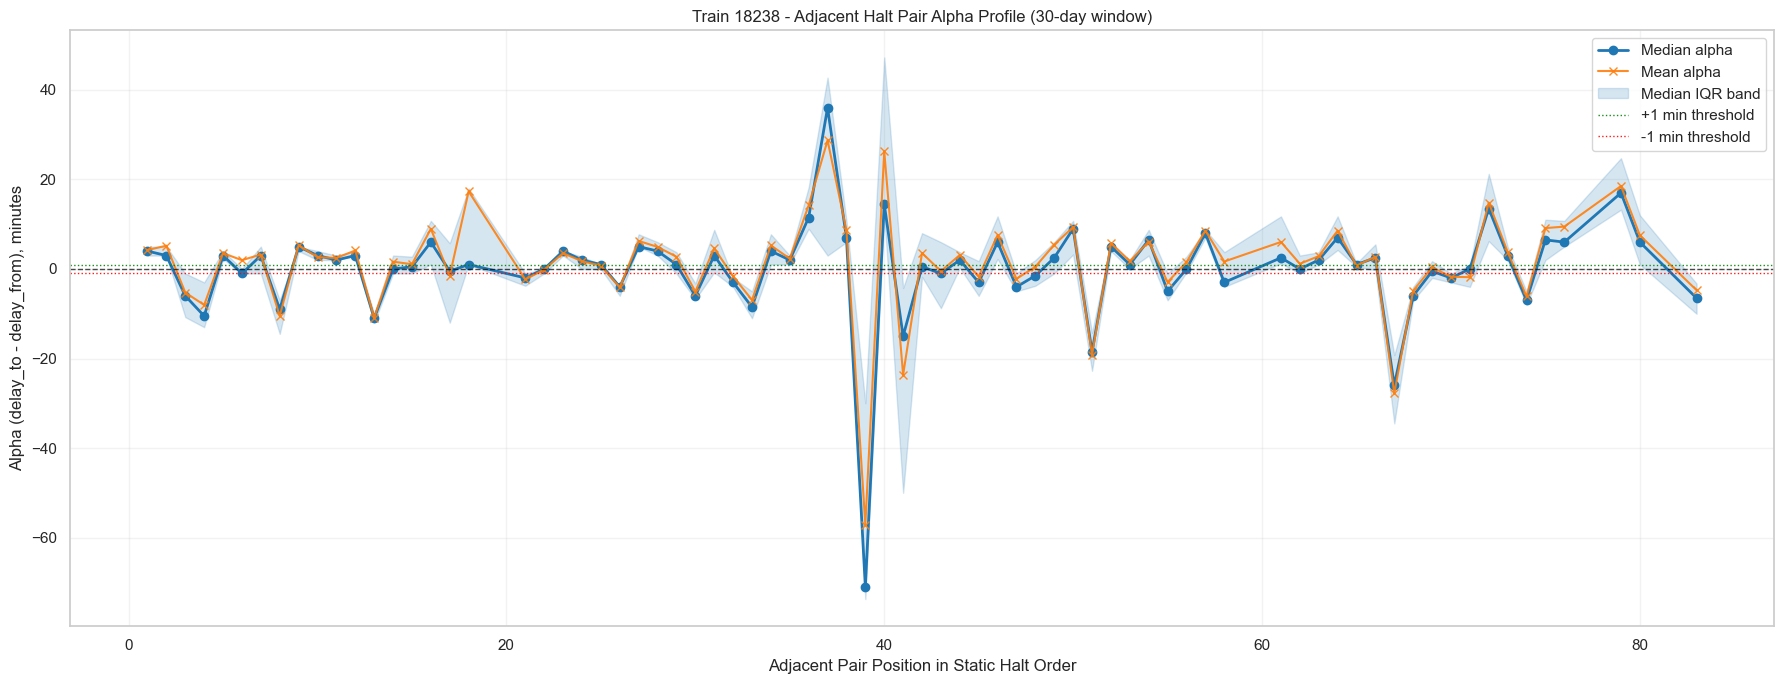

,seq_from,pair_label,n_journeys,coverage_ratio,alpha_median_min,alpha_mean_min,alpha_q25_min,alpha_q75_min,alpha_iqr_min,alpha_std_min,alpha_mad_min,median_zone,mean_zone
0,1,ASR -> JNL,30.0,1.000000,4.0,4.233333,3.00,5.00,2.00,2.062528,1.0,adds_delay,adds_delay
1,2,JNL -> BEAS,30.0,1.000000,3.0,5.200000,3.00,5.00,2.00,5.378117,1.0,adds_delay,adds_delay
2,3,BEAS -> JUC,30.0,1.000000,-6.0,-5.266667,-10.75,-1.00,9.75,6.617288,5.0,covers_up,covers_up
3,4,JUC -> JRC,30.0,1.000000,-10.5,-8.033333,-13.00,-3.00,10.00,5.991277,3.5,covers_up,covers_up
4,5,JRC -> PGW,30.0,1.000000,3.0,3.533333,2.25,4.00,1.75,2.192988,1.0,adds_delay,adds_delay
...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,75,SKS -> DGG,30.0,1.000000,6.5,9.133333,2.00,11.00,9.00,12.283247,4.5,adds_delay,adds_delay
71,76,DGG -> RJN,30.0,1.000000,6.0,9.466667,5.00,10.75,5.75,7.069767,1.5,adds_delay,adds_delay
72,79,BPHB -> R,26.0,0.866667,17.0,18.538462,13.25,24.75,11.50,9.798901,7.0,adds_delay,adds_delay
73,80,R -> TLD,29.0,0.966667,6.0,7.517241,1.00,12.00,11.00,7.590505,6.0,adds_delay,adds_delay


In [10]:
# Display alpha outputs: ranked tables, diagnostics, and alpha profile plot
import matplotlib.pyplot as plt

if "alpha_pair_stats_full_18238" not in globals():
    raise NameError("alpha_pair_stats_full_18238 not found. Run previous alpha computation cell first.")

alpha_rankable_18238 = alpha_pair_stats_full_18238.dropna(subset=["alpha_median_min", "alpha_mean_min"]).copy()
alpha_rankable_18238 = alpha_rankable_18238.sort_values("seq_from").reset_index(drop=True)

low_coverage_pairs_18238 = alpha_pair_stats_full_18238[
    alpha_pair_stats_full_18238["coverage_ratio"].fillna(0) < 0.5
].copy()

print("Alpha zones by median threshold (|alpha| >= 1 minute):")
print(alpha_rankable_18238["median_zone"].value_counts())
print("\nAlpha zones by mean threshold (|alpha| >= 1 minute):")
print(alpha_rankable_18238["mean_zone"].value_counts())

print("\nTop 10 delay-adding pairs by median alpha:")
display(
    alpha_rankable_18238.sort_values("alpha_median_min", ascending=False)
    [["pair_label", "n_journeys", "coverage_ratio", "alpha_median_min", "alpha_mean_min", "alpha_iqr_min"]]
    .head(10)
)

print("Top 10 cover-up pairs by median alpha:")
display(
    alpha_rankable_18238.sort_values("alpha_median_min", ascending=True)
    [["pair_label", "n_journeys", "coverage_ratio", "alpha_median_min", "alpha_mean_min", "alpha_iqr_min"]]
    .head(10)
)

print("Top 10 delay-adding pairs by mean alpha:")
display(
    alpha_rankable_18238.sort_values("alpha_mean_min", ascending=False)
    [["pair_label", "n_journeys", "coverage_ratio", "alpha_median_min", "alpha_mean_min", "alpha_iqr_min"]]
    .head(10)
)

print("Top 10 cover-up pairs by mean alpha:")
display(
    alpha_rankable_18238.sort_values("alpha_mean_min", ascending=True)
    [["pair_label", "n_journeys", "coverage_ratio", "alpha_median_min", "alpha_mean_min", "alpha_iqr_min"]]
    .head(10)
)

print("Pairs with low journey coverage (< 50%):")
if low_coverage_pairs_18238.empty:
    print("None")
else:
    display(
        low_coverage_pairs_18238[
            ["pair_label", "n_journeys", "coverage_ratio", "alpha_median_min", "alpha_mean_min", "alpha_iqr_min"]
        ].sort_values("coverage_ratio")
    )

# Alpha profile along route sequence
x_vals = alpha_rankable_18238["seq_from"].values
median_vals = alpha_rankable_18238["alpha_median_min"].values
mean_vals = alpha_rankable_18238["alpha_mean_min"].values
q25_vals = alpha_rankable_18238["alpha_q25_min"].values
q75_vals = alpha_rankable_18238["alpha_q75_min"].values

plt.figure(figsize=(18, 7))
plt.plot(x_vals, median_vals, marker="o", linewidth=2, label="Median alpha", color="#1f77b4")
plt.plot(x_vals, mean_vals, marker="x", linewidth=1.5, label="Mean alpha", color="#ff7f0e", alpha=0.9)
plt.fill_between(x_vals, q25_vals, q75_vals, color="#1f77b4", alpha=0.18, label="Median IQR band")

plt.axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.7)
plt.axhline(1, color="green", linewidth=1, linestyle=":", alpha=0.9, label="+1 min threshold")
plt.axhline(-1, color="red", linewidth=1, linestyle=":", alpha=0.9, label="-1 min threshold")

plt.title("Train 18238 - Adjacent Halt Pair Alpha Profile (30-day window)")
plt.xlabel("Adjacent Pair Position in Static Halt Order")
plt.ylabel("Alpha (delay_to - delay_from), minutes")
plt.legend(loc="upper right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Optional compact route-ordered table for downstream analysis/export
display(
    alpha_rankable_18238[
        [
            "seq_from",
            "pair_label",
            "n_journeys",
            "coverage_ratio",
            "alpha_median_min",
            "alpha_mean_min",
            "alpha_q25_min",
            "alpha_q75_min",
            "alpha_iqr_min",
            "alpha_std_min",
            "alpha_mad_min",
            "median_zone",
            "mean_zone",
        ]
    ].sort_values("seq_from")
)

## How to interpret the alpha outputs for 18238

Reading the station-pair alpha table:
- alpha_median_min is the robust typical delay change from station_from to station_to across journeys.
- alpha_mean_min is the average delay change and is more sensitive to rare spikes.
- Positive alpha means delay tends to increase on that segment.
- Negative alpha means delay tends to decrease on that segment (cover-up).
- alpha_iqr_min captures variability across journeys. Lower values indicate more stable behavior.
- n_journeys and coverage_ratio indicate reliability. Prefer high-coverage pairs for decisions.

Reading the alpha profile plot:
- Segments above 0 are delay-adding zones.
- Segments below 0 are recovery zones.
- Threshold lines at +1 and -1 minute highlight practically meaningful effects.
- Median and mean diverging strongly on a segment usually indicates outlier journeys.

How to use this operationally:
- Prioritize persistent high-positive alpha segments as intervention candidates.
- Preserve or learn from persistent negative alpha segments where recovery is consistent.
- Treat low-coverage segments as provisional until more journeys are collected.
- Use median-driven ranking as primary signal and mean-driven ranking as sensitivity check.

## Simple Interpretation of 18238 Alpha Results

What this analysis is doing in simple terms:
- For each adjacent halt-station pair, we check how much delay changed between station A and station B.
- If the value is positive, delay was added on that segment.
- If the value is negative, delay was recovered (cover-up) on that segment.

What the current 30-day result says:
- There is no single straight trend for the full route. The train alternates between adding delay and recovering delay in different sections.
- Delay-adding segments are more frequent than recovery segments in this window.
- Some segments show very strong jumps (both up and down), so local route sections matter a lot.

Important examples from your output:
- Strong delay addition: MTJ -> RKM, BPHB -> R, DHO -> MRA.
- Strong delay recovery: AGC -> DHO, KATL -> NGP, DUA -> BINA.
- BYT -> BYL appears as a recovery segment in this window (negative alpha), so it is actively helping cover up delay on average.

How to trust the results:
- Pairs with high journey coverage (close to 30/30) are more reliable.
- Pairs with low coverage should be treated as provisional.
- Median alpha is the primary signal (more robust). Mean alpha is useful as a sensitivity check.

How to use this practically:
- Focus intervention on repeated high-positive alpha segments (persistent delay builders).
- Study repeated high-negative alpha segments (good recovery behavior) and replicate those operational patterns elsewhere.
- Recompute this monthly so these segment-level behaviors are tracked over time.